In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
!pip install autoviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.5/67.5 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.4/175.4 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 66.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 255.9/255.9 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 43.4 MB/s eta 0:00:00
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.7.2
    Uninstalling matplotlib-3.7.2:
      Successfully uninstalled matplotlib-3.7.2
  Attempting uninstall: xgboost
    Found existing installation: xgboost 2.0.3
    Uninstalling xgboost-2.0.3:
      Successfully uninstalled xgboost-2.0.3
  Attempting uninstall: seaborn
    Found existing installation: seaborn 0.12.2
    Uninstalling seaborn-0.12.2:
      Successfully uninstalled seaborn-0.12.2
ERROR: pip's dependency resolver does not cur


<div style="margin:20px 0;padding:20px;border-left:5px solid #2d6a4f;background-color:#fafafa;font-family:'Verdana',sans-serif;box-shadow:0 2px 4px rgba(0,0,0,0.1);">

  <h2 style="font-size:1.6rem;font-weight:700;color:#2d6a4f;margin-bottom:12px;">
    Importing Libraries
  </h2>

</div>

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
import plotly.express as px
from IPython.display import display, HTML
import warnings
warnings.filterwarnings("ignore")


<div style="margin:20px 0;padding:20px;border-left:5px solid #2d6a4f;background-color:#fafafa;font-family:'Verdana',sans-serif;box-shadow:0 2px 4px rgba(0,0,0,0.1);">

  <h2 style="font-size:1.6rem;font-weight:700;color:#2d6a4f;margin-bottom:12px;">
    Data Loading
  </h2>

</div>

In [4]:
# Load data
train = pd.read_csv('/kaggle/input/playground-series-s5e6/train.csv')
test = pd.read_csv('/kaggle/input/playground-series-s5e6/train.csv')

# Set index
train.set_index('id', inplace=True)
test.set_index('id', inplace=True)

train.head(5)

,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
id,,,,,,,,,
0,37,70,36,Clayey,Sugarcane,36,4,5,28-28
1,27,69,65,Sandy,Millets,30,6,18,28-28
2,29,63,32,Sandy,Millets,24,12,16,17-17-17
3,35,62,54,Sandy,Barley,39,12,4,10-26-26
4,35,58,43,Red,Paddy,37,2,16,DAP


<div style="margin:20px 0;padding:20px;border-left:5px solid #2d6a4f;background-color:#fafafa;font-family:'Verdana',sans-serif;box-shadow:0 2px 4px rgba(0,0,0,0.1);">

  <h2 style="font-size:1.6rem;font-weight:700;color:#2d6a4f;margin-bottom:12px;">
    Fertilizer Distribution Visualization
  </h2>
  <p style="font-size:1rem;color:#333333;line-height:1.5;"> Plotting the counts and percentage of each fertilizer class to see if there is data imbalaces
  </p>

</div>


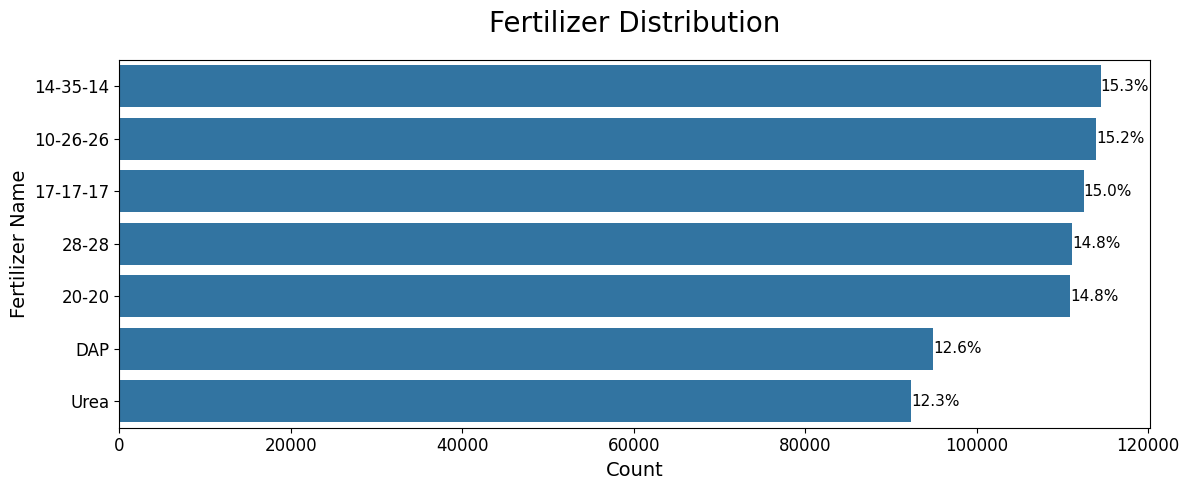

In [5]:
# Target distribution
plt.figure(figsize=(12, 5))
ax = sns.countplot(y=train['Fertilizer Name'], 
                 order=train['Fertilizer Name'].value_counts().index)
plt.title('Fertilizer Distribution', fontsize=20, pad=20)
plt.xlabel('Count', fontsize=14)
plt.ylabel('Fertilizer Name', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Add annotations
for p in ax.patches:
    width = p.get_width()
    plt.annotate(f'{width/train.shape[0]:.1%}', 
                 (width + 20, p.get_y() + p.get_height()/2),
                 ha='left', va='center', fontsize=11)

plt.tight_layout()
plt.show()

<div style="margin:20px 0;padding:20px;border-left:5px solid #2d6a4f;background-color:#fafafa;font-family:'Verdana',sans-serif;box-shadow:0 2px 4px rgba(0,0,0,0.1);">

  <h2 style="font-size:1.6rem;font-weight:700;color:#2d6a4f;margin-bottom:12px;">
    Numerical Feature Distribution Analysis
  </h2>
  <p style="font-size:1rem;color:#333333;line-height:1.5;">
    Generate a 2×3 grid of histograms with KDE overlays for key numerical predictors—Temperature, Humidity, Moisture, Nitrogen, Potassium, and Phosphorous—using 30 bins each. Each subplot includes descriptive statistics annotations (mean, standard deviation, min, max) positioned at relative coordinates to facilitate rapid visual assessment of central tendency and dispersion. 

</div>


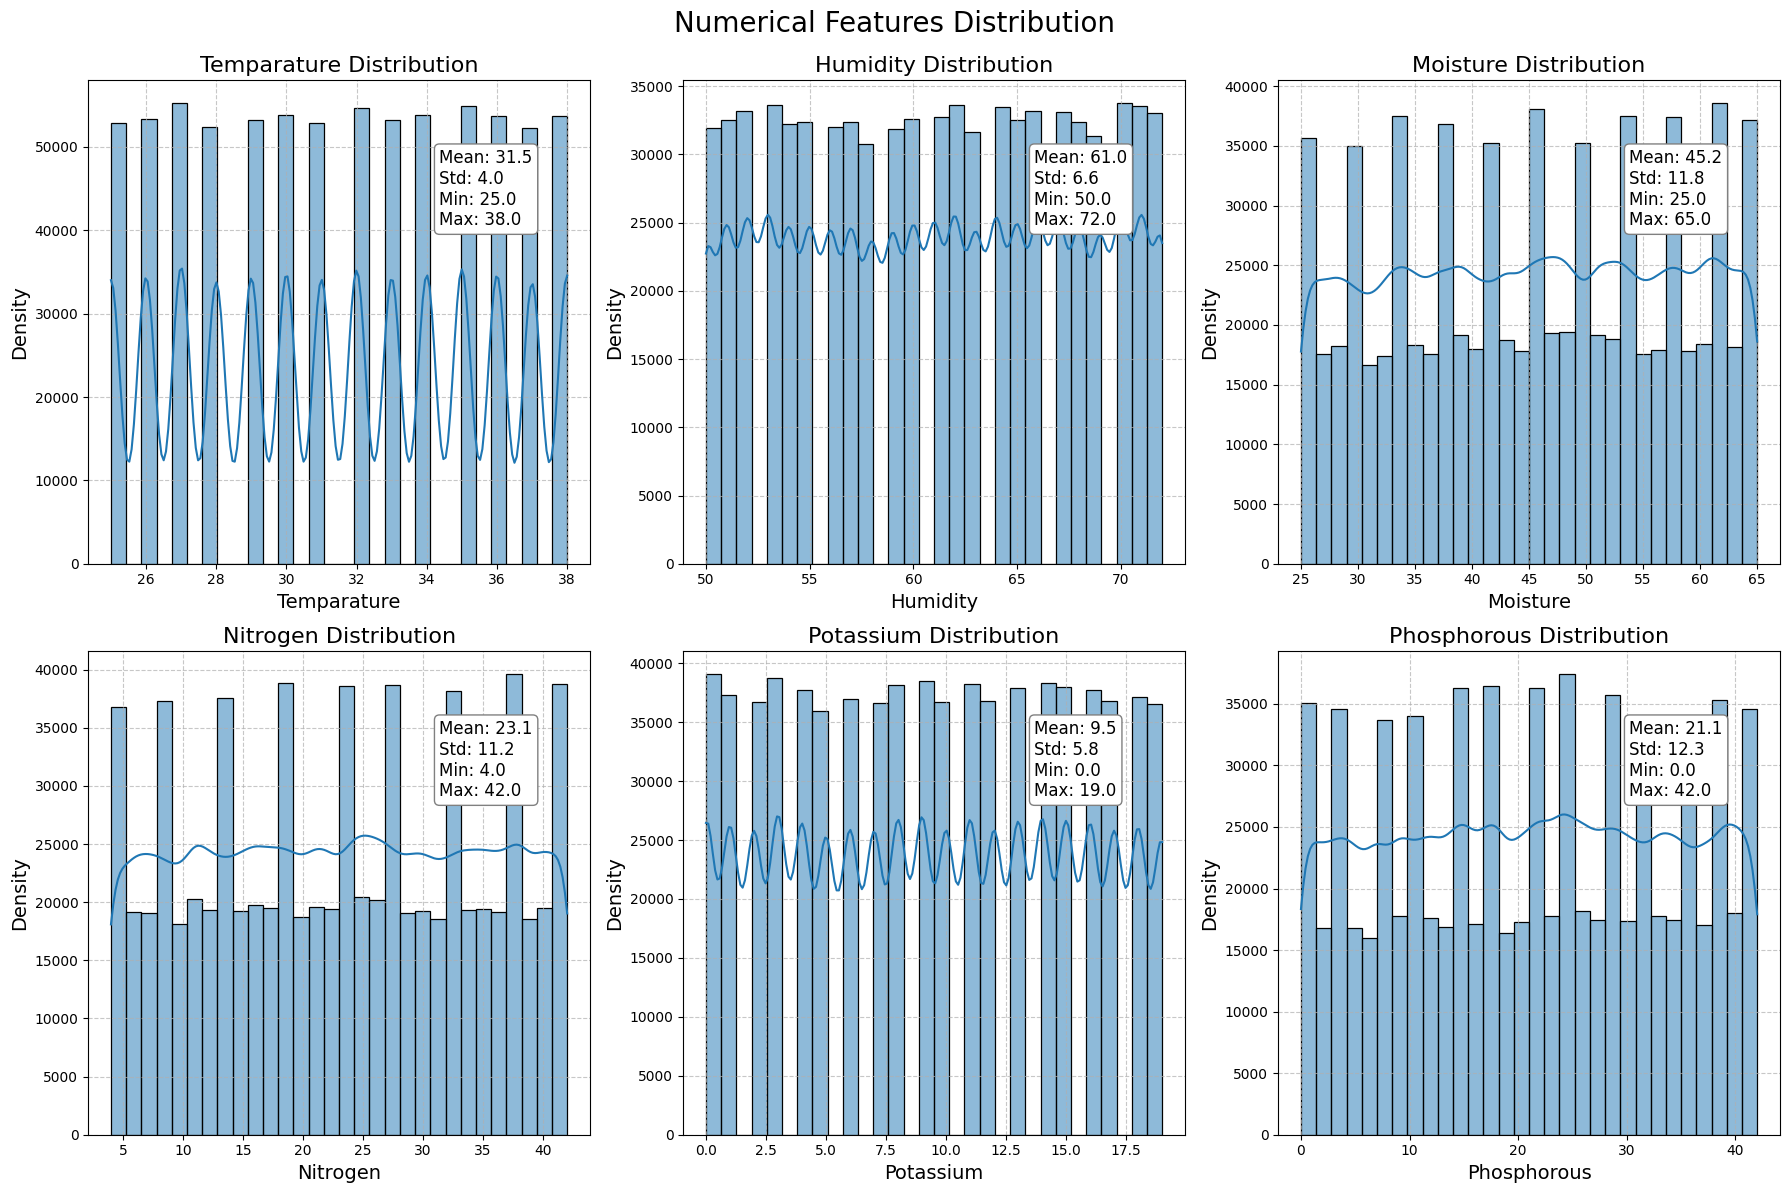

In [6]:
# Select numerical features
num_features = ['Temparature', 'Humidity', 'Moisture', 
               'Nitrogen', 'Potassium', 'Phosphorous']

# Plot distributions
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(num_features):
    sns.histplot(train[col], kde=True, ax=axes[i], bins=30)
    axes[i].set_title(f'{col} Distribution', fontsize=16)
    axes[i].set_xlabel(col, fontsize=14)
    axes[i].set_ylabel('Density', fontsize=14)
    axes[i].grid(True, linestyle='--', alpha=0.7)
    
    # Add statistics
    stats = train[col].describe()
    text = f"Mean: {stats['mean']:.1f}\nStd: {stats['std']:.1f}\nMin: {stats['min']:.1f}\nMax: {stats['max']:.1f}"
    axes[i].annotate(text, xy=(0.7, 0.7), xycoords='axes fraction', 
                    fontsize=12, bbox=dict(boxstyle="round,pad=0.3", fc='white', ec="gray", lw=1))

plt.suptitle('Numerical Features Distribution', fontsize=20, y=0.99)
plt.tight_layout()
plt.show()

<div style="margin:20px 0;padding:20px;border-left:5px solid #2d6a4f;background-color:#fafafa;font-family:'Verdana',sans-serif;box-shadow:0 2px 4px rgba(0,0,0,0.1);">

  <h2 style="font-size:1.6rem;font-weight:700;color:#2d6a4f;margin-bottom:12px;">
    Categorical Feature Distribution Visualization
  </h2>
  <p style="font-size:1rem;color:#333333;line-height:1.5;">
    Visualize the frequency of each category in Soil Type and Crop Type to quickly identify any class imbalances.
  </p>

</div>


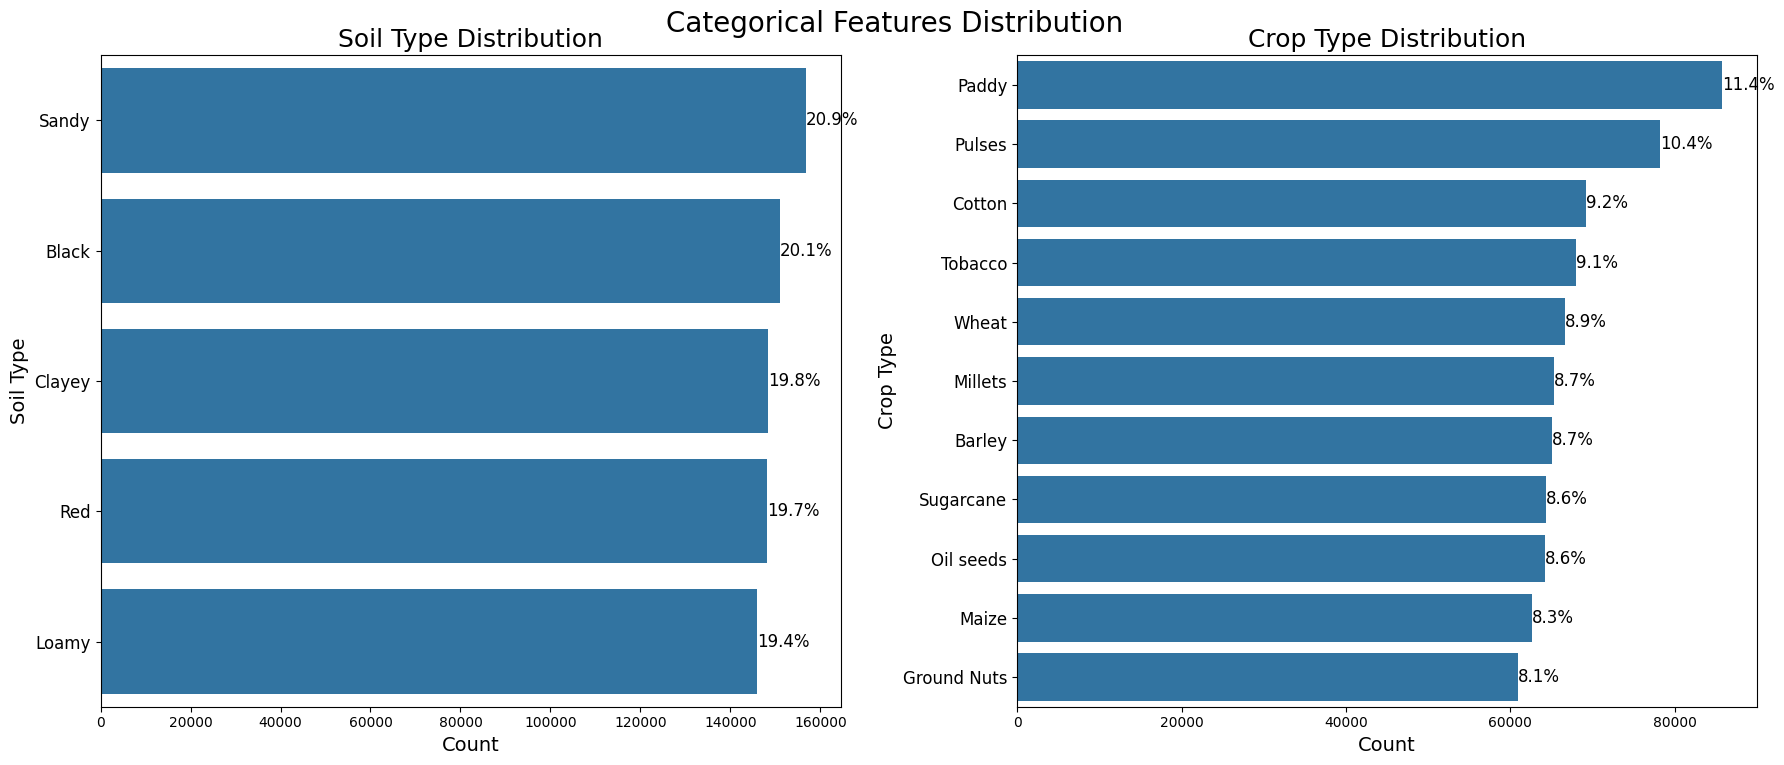

In [7]:
# Categorical features
cat_features = ['Soil Type', 'Crop Type']

# Plot distributions
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for i, col in enumerate(cat_features):
    counts = train[col].value_counts()
    ax = sns.barplot(x=counts.values, y=counts.index, ax=axes[i])
    axes[i].set_title(f'{col} Distribution', fontsize=18)
    axes[i].set_xlabel('Count', fontsize=14)
    axes[i].set_ylabel(col, fontsize=14)
    axes[i].tick_params(axis='y', labelsize=12)
    
    # Add percentages
    total = len(train)
    for p in ax.patches:
        width = p.get_width()
        ax.text(width + 20, p.get_y() + p.get_height()/2, 
                f'{width/total:.1%}', 
                ha='left', va='center', fontsize=12)

plt.suptitle('Categorical Features Distribution', fontsize=20, y=0.95)
plt.tight_layout()
plt.show()

<div style="margin:20px 0;padding:20px;border-left:5px solid #2d6a4f;background-color:#fafafa;font-family:'Verdana',sans-serif;box-shadow:0 2px 4px rgba(0,0,0,0.1);">

  <h2 style="font-size:1.6rem;font-weight:700;color:#2d6a4f;margin-bottom:12px;">
    Fertilizer Preferences Analysis
  </h2>
  <p style="font-size:1rem;color:#333333;line-height:1.5;">
    Generate normalized heatmaps to compare fertilizer usage patterns across crop and soil types, highlighting relative preferences and interaction trends.
  </p>

</div>


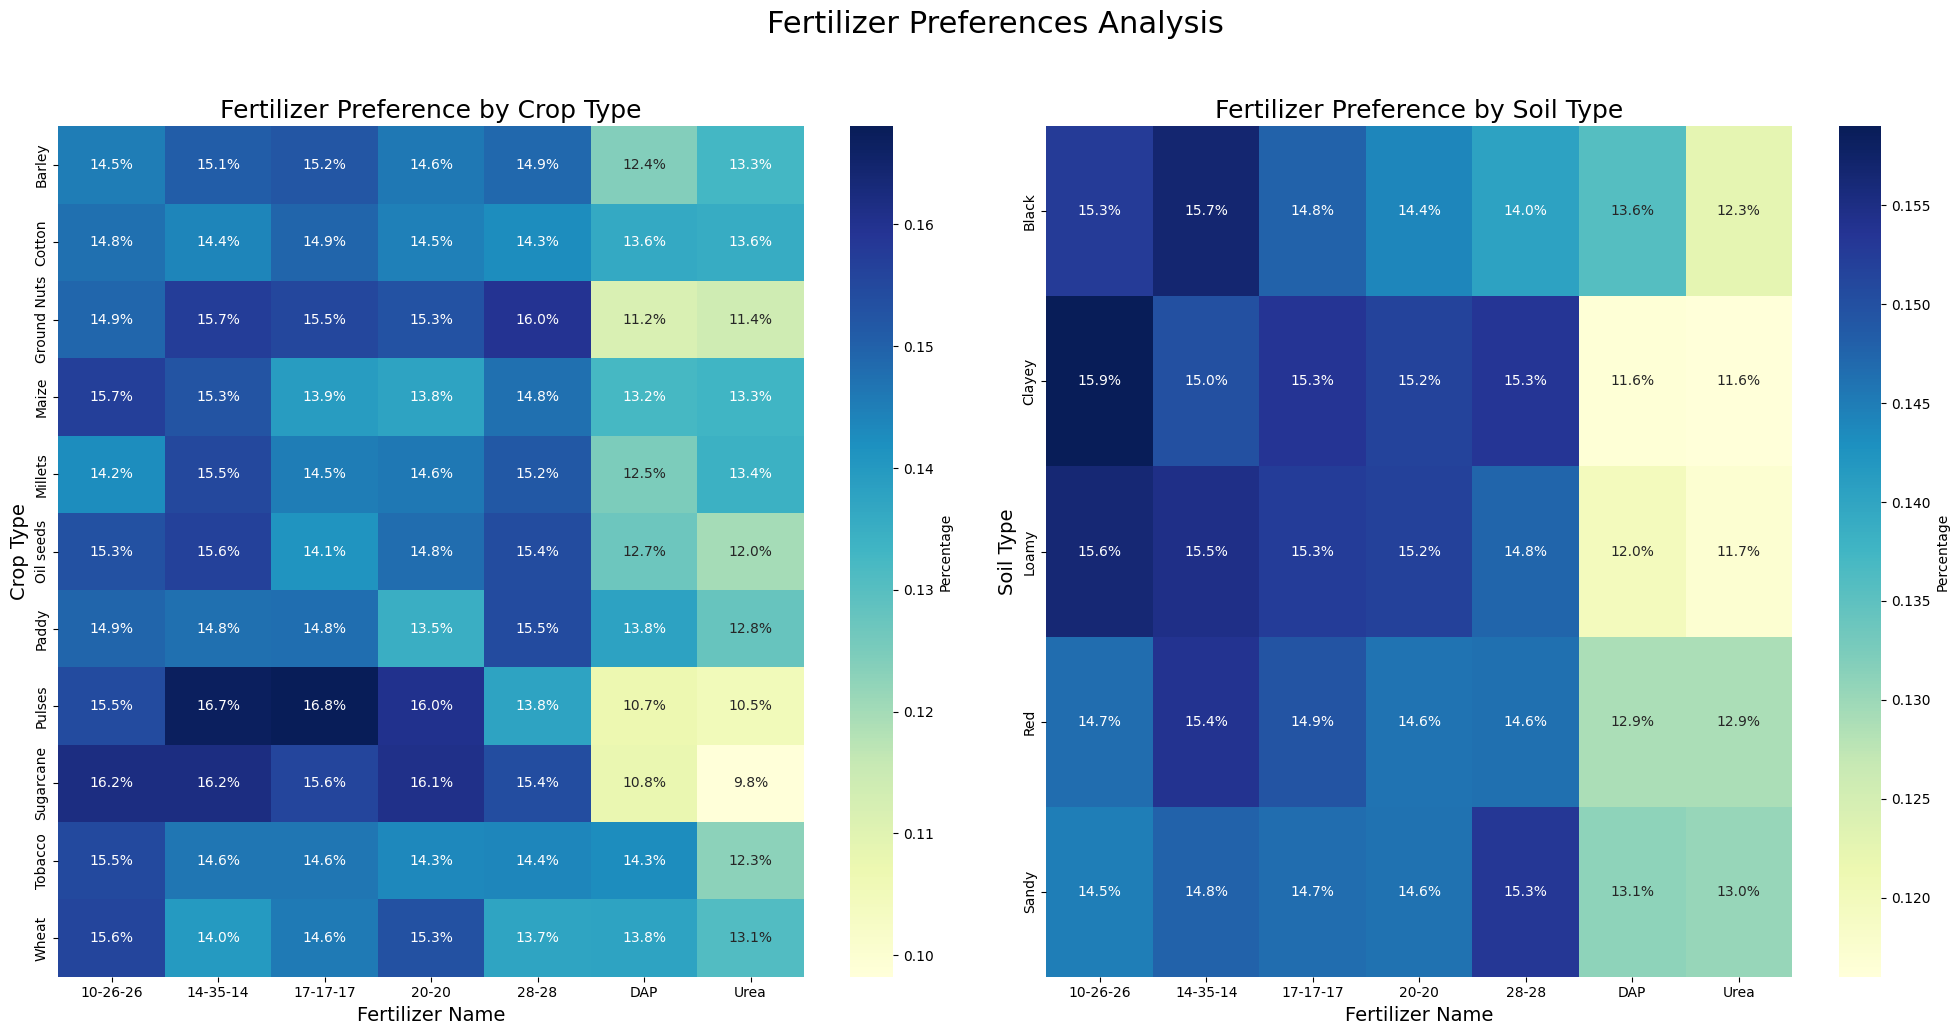

In [8]:
# Create cross-tab visualizations
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# Crop vs Fertilizer
ct1 = pd.crosstab(train['Crop Type'], train['Fertilizer Name'], normalize='index')
sns.heatmap(ct1, annot=True, fmt='.1%', cmap='YlGnBu', ax=axes[0], cbar_kws={'label': 'Percentage'})
axes[0].set_title('Fertilizer Preference by Crop Type', fontsize=18)
axes[0].set_xlabel('Fertilizer Name', fontsize=14)
axes[0].set_ylabel('Crop Type', fontsize=14)

# Soil vs Fertilizer
ct2 = pd.crosstab(train['Soil Type'], train['Fertilizer Name'], normalize='index')
sns.heatmap(ct2, annot=True, fmt='.1%', cmap='YlGnBu', ax=axes[1], cbar_kws={'label': 'Percentage'})
axes[1].set_title('Fertilizer Preference by Soil Type', fontsize=18)
axes[1].set_xlabel('Fertilizer Name', fontsize=14)
axes[1].set_ylabel('Soil Type', fontsize=14)

plt.suptitle('Fertilizer Preferences Analysis', fontsize=22, y=1.03 )
plt.tight_layout()
plt.show()

<div style="margin:20px 0;padding:20px;border-left:5px solid #2d6a4f;background-color:#fafafa;font-family:'Verdana',sans-serif;box-shadow:0 2px 4px rgba(0,0,0,0.1);">

  <h2 style="font-size:1.6rem;font-weight:700;color:#2d6a4f;margin-bottom:12px;">
    Soil Nutrient Profiles by Fertilizer
  </h2>
  <p style="font-size:1rem;color:#333333;line-height:1.5;">
    Display boxplots of nitrogen, phosphorous, and potassium levels grouped by fertilizer type to compare distributions and detect outliers.
  </p>

</div>


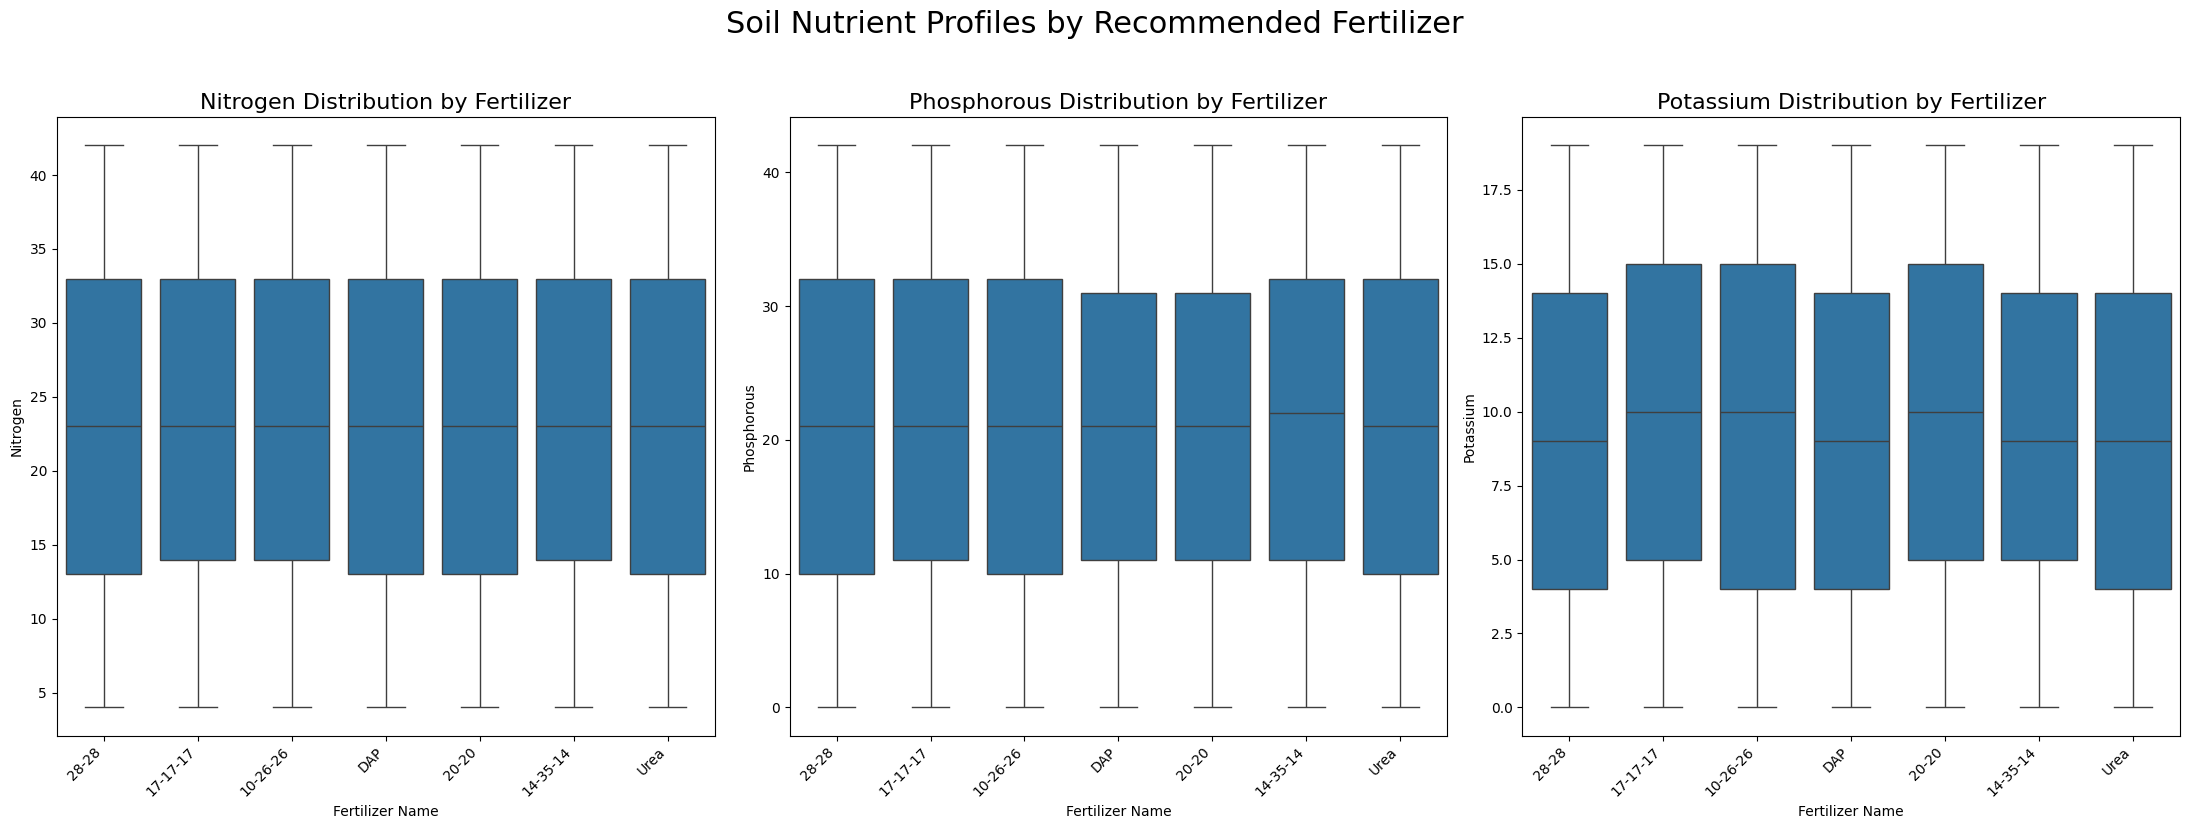

In [9]:
# Nutrient analysis
fig, axes = plt.subplots(1, 3, figsize=(22, 8))

# Nitrogen
sns.boxplot(x='Fertilizer Name', y='Nitrogen', data=train, ax=axes[0])
axes[0].set_title('Nitrogen Distribution by Fertilizer', fontsize=16)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')

# Phosphorous
sns.boxplot(x='Fertilizer Name', y='Phosphorous', data=train, ax=axes[1])
axes[1].set_title('Phosphorous Distribution by Fertilizer', fontsize=16)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')

# Potassium
sns.boxplot(x='Fertilizer Name', y='Potassium', data=train, ax=axes[2])
axes[2].set_title('Potassium Distribution by Fertilizer', fontsize=16)
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=45, ha='right')

plt.suptitle('Soil Nutrient Profiles by Recommended Fertilizer', fontsize=22, y=1.03)
plt.tight_layout()
plt.show()

<div style="margin:20px 0;padding:20px;border-left:5px solid #2d6a4f;background-color:#fafafa;font-family:'Verdana',sans-serif;box-shadow:0 2px 4px rgba(0,0,0,0.1);">

  <h2 style="font-size:1.6rem;font-weight:700;color:#2d6a4f;margin-bottom:12px;">
    Feature Correlation Analysis
  </h2>
  <p style="font-size:1rem;color:#333333;line-height:1.5;">
    Label‐encode categorical variables and plot a masked correlation heatmap to reveal pairwise relationships and potential multicollinearity among features.
  </p>

</div>


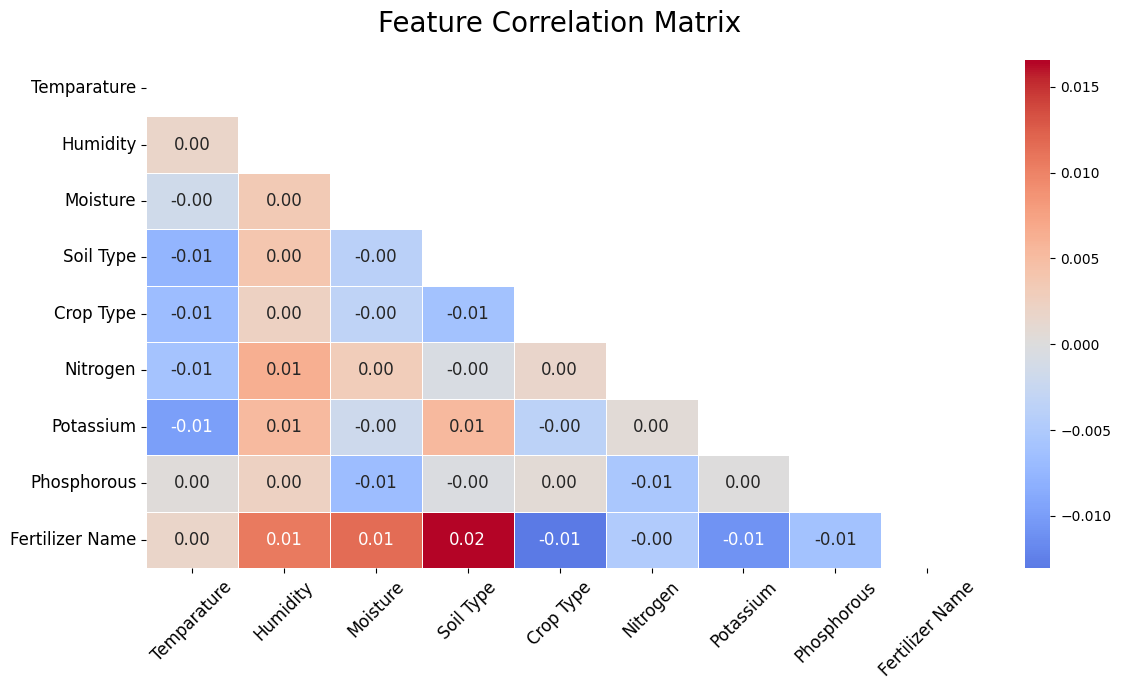

In [10]:
# Encode categorical features for correlation
encoder = LabelEncoder()
train_encoded = train.copy()
train_encoded['Soil Type'] = encoder.fit_transform(train['Soil Type'])
train_encoded['Crop Type'] = encoder.fit_transform(train['Crop Type'])
train_encoded['Fertilizer Name'] = encoder.fit_transform(train['Fertilizer Name'])

# Correlation matrix
plt.figure(figsize=(12, 7))
corr = train_encoded.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', 
           center=0, linewidths=0.5, annot_kws={"size": 12})
plt.title('Feature Correlation Matrix', fontsize=20, pad=20)
plt.xticks(fontsize=12, rotation=45)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

<div style="margin:20px 0;padding:20px;border-left:5px solid #2d6a4f;background-color:#fafafa;font-family:'Verdana',sans-serif;box-shadow:0 2px 4px rgba(0,0,0,0.1);">

  <h2 style="font-size:1.6rem;font-weight:700;color:#2d6a4f;margin-bottom:12px;">
    Feature Relationships by Fertilizer Type
  </h2>
  <p style="font-size:1rem;color:#333333;line-height:1.5;">
    Plot pairwise scatterplots for Temperature, Humidity, Nitrogen, and Phosphorous on a sample of 1,000 records, colored by fertilizer category to highlight underlying correlations and cluster separations.
  </p>

</div>


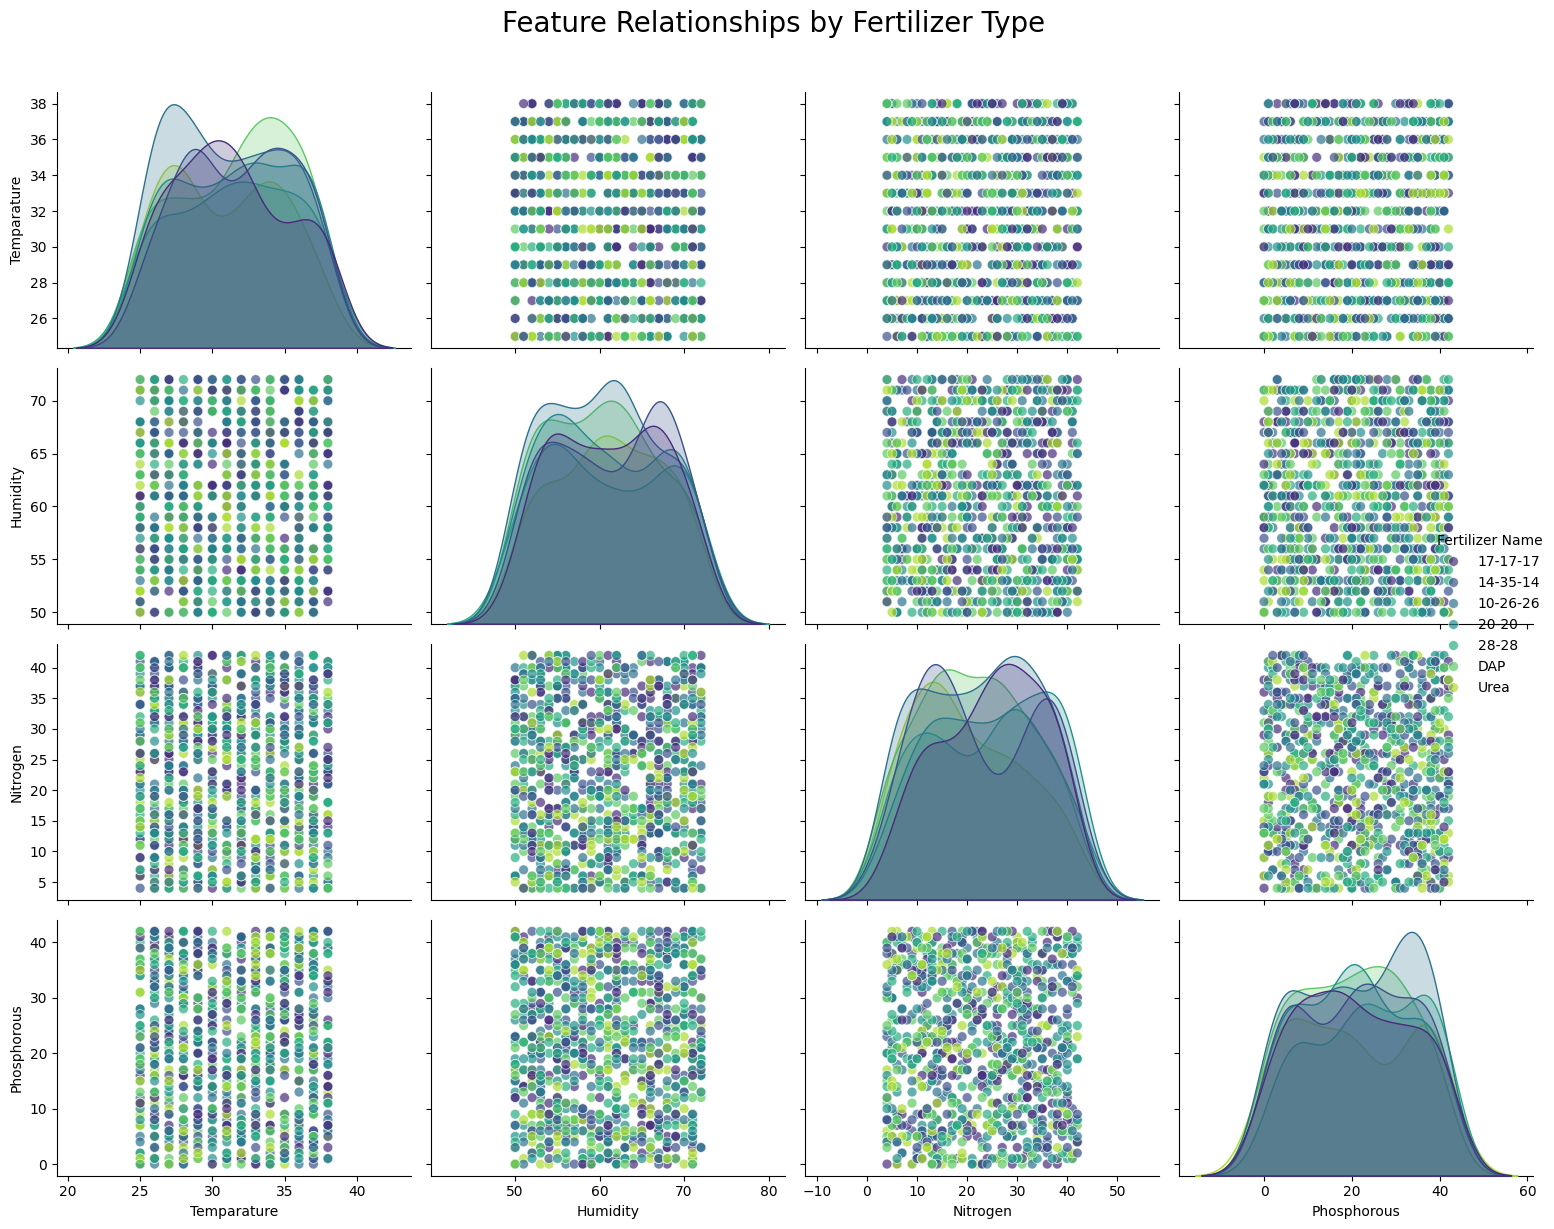

In [11]:
# Sample data for performance
sample_df = train.sample(1000, random_state=42)

# Create pairplot
g = sns.pairplot(sample_df, hue='Fertilizer Name', 
                vars=['Temparature', 'Humidity', 'Nitrogen', 'Phosphorous'], 
                palette='viridis', height=3, aspect=1.2,
                plot_kws={'alpha': 0.7, 's': 50})
g.fig.suptitle('Feature Relationships by Fertilizer Type', y=1.02, fontsize=20)
plt.tight_layout()
plt.show()

Imported v0.1.905. Please call AutoViz in this sequence:
    AV = AutoViz_Class()
    %matplotlib inline
    dfte = AV.AutoViz(filename, sep=',', depVar='', dfte=None, header=0, verbose=1, lowess=False,
               chart_format='svg',max_rows_analyzed=150000,max_cols_analyzed=30, save_plot_dir=None)
    Since nrows is smaller than dataset, loading random sample of 150000 rows into pandas...
Shape of your Data Set loaded: (150000, 9)
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  0
    Number of Integer-Categorical Columns =  6
    Number of String-Categorical Columns =  2
    Number of Factor-Categorical Columns =  0
    Number of String-Boolean Columns =  0
    Number of Numeric-Boolean Columns =  0


,Data Type,Missing Values%,Unique Values%,Minimum Value,Maximum Value,DQ Issue
Temparature,int64,0.000000,0,25.000000,38.000000,No issue
Humidity,int64,0.000000,0,50.000000,72.000000,No issue
Moisture,int64,0.000000,0,25.000000,65.000000,No issue
Soil Type,object,0.000000,0,,,No issue
Crop Type,object,0.000000,0,,,No issue
Nitrogen,int64,0.000000,0,4.000000,42.000000,No issue
Potassium,int64,0.000000,0,0.000000,19.000000,No issue
Phosphorous,int64,0.000000,0,0.000000,42.000000,No issue
Fertilizer Name,object,0.000000,0,,,Target column


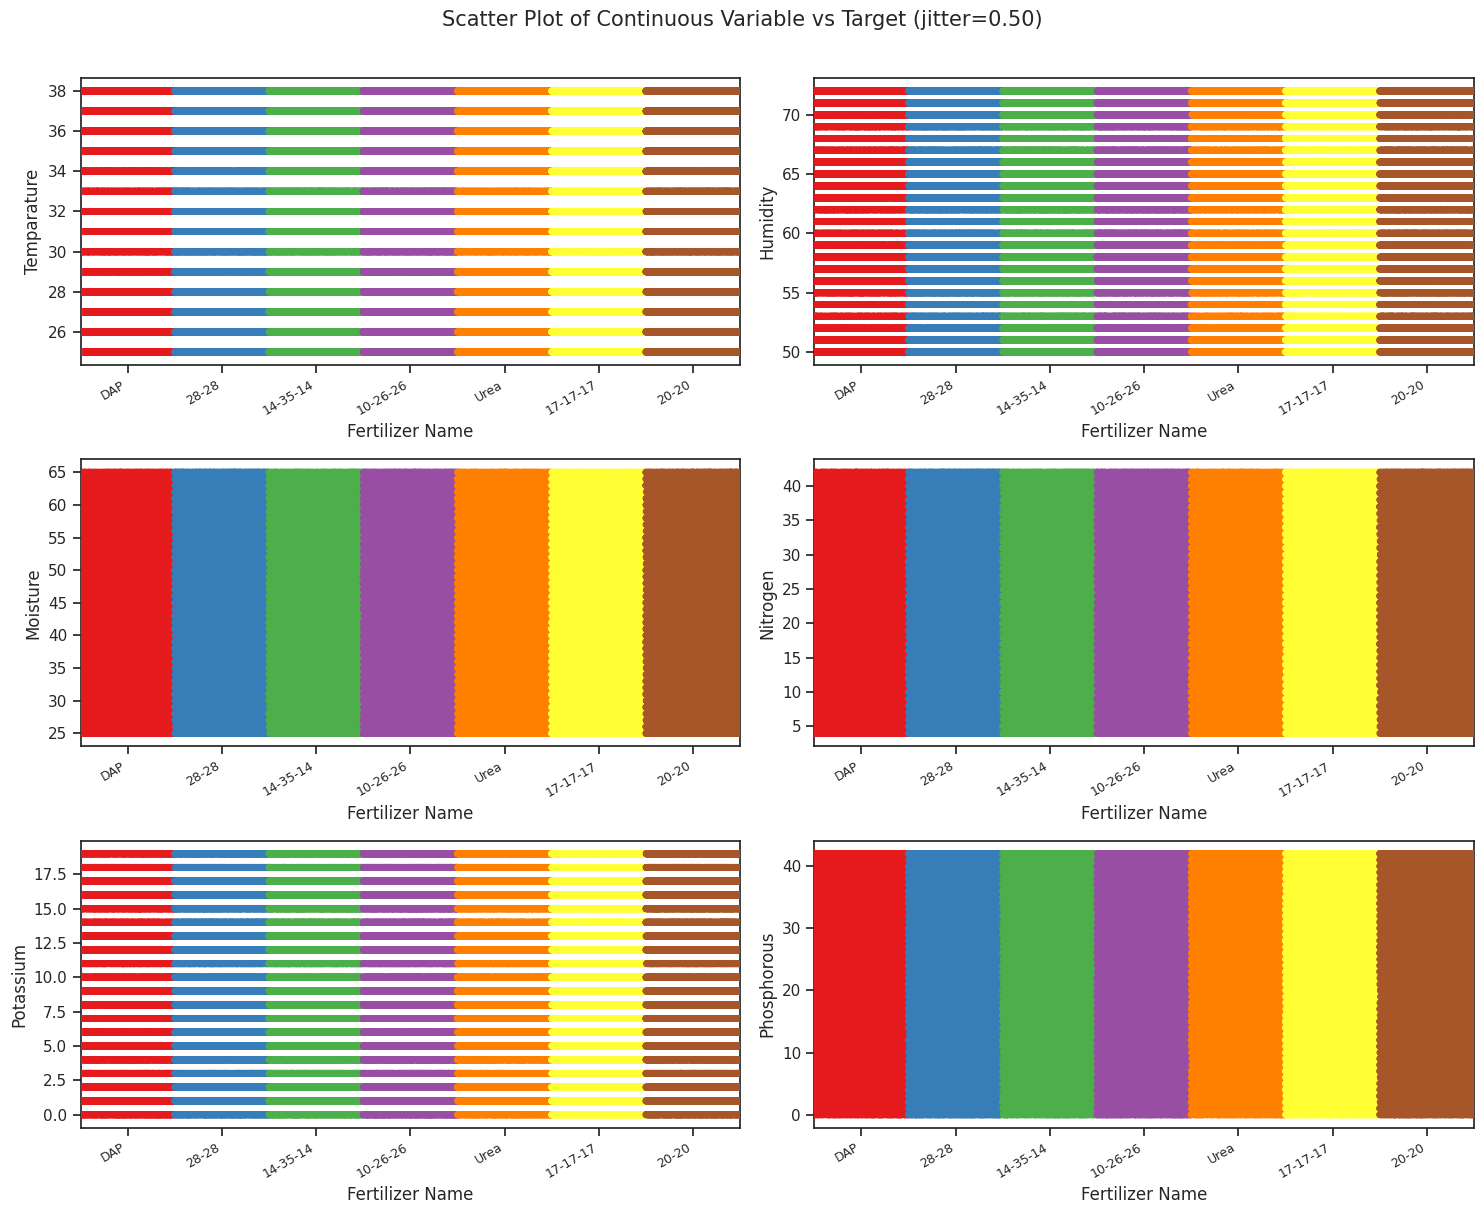

Total Number of Scatter Plots = 21


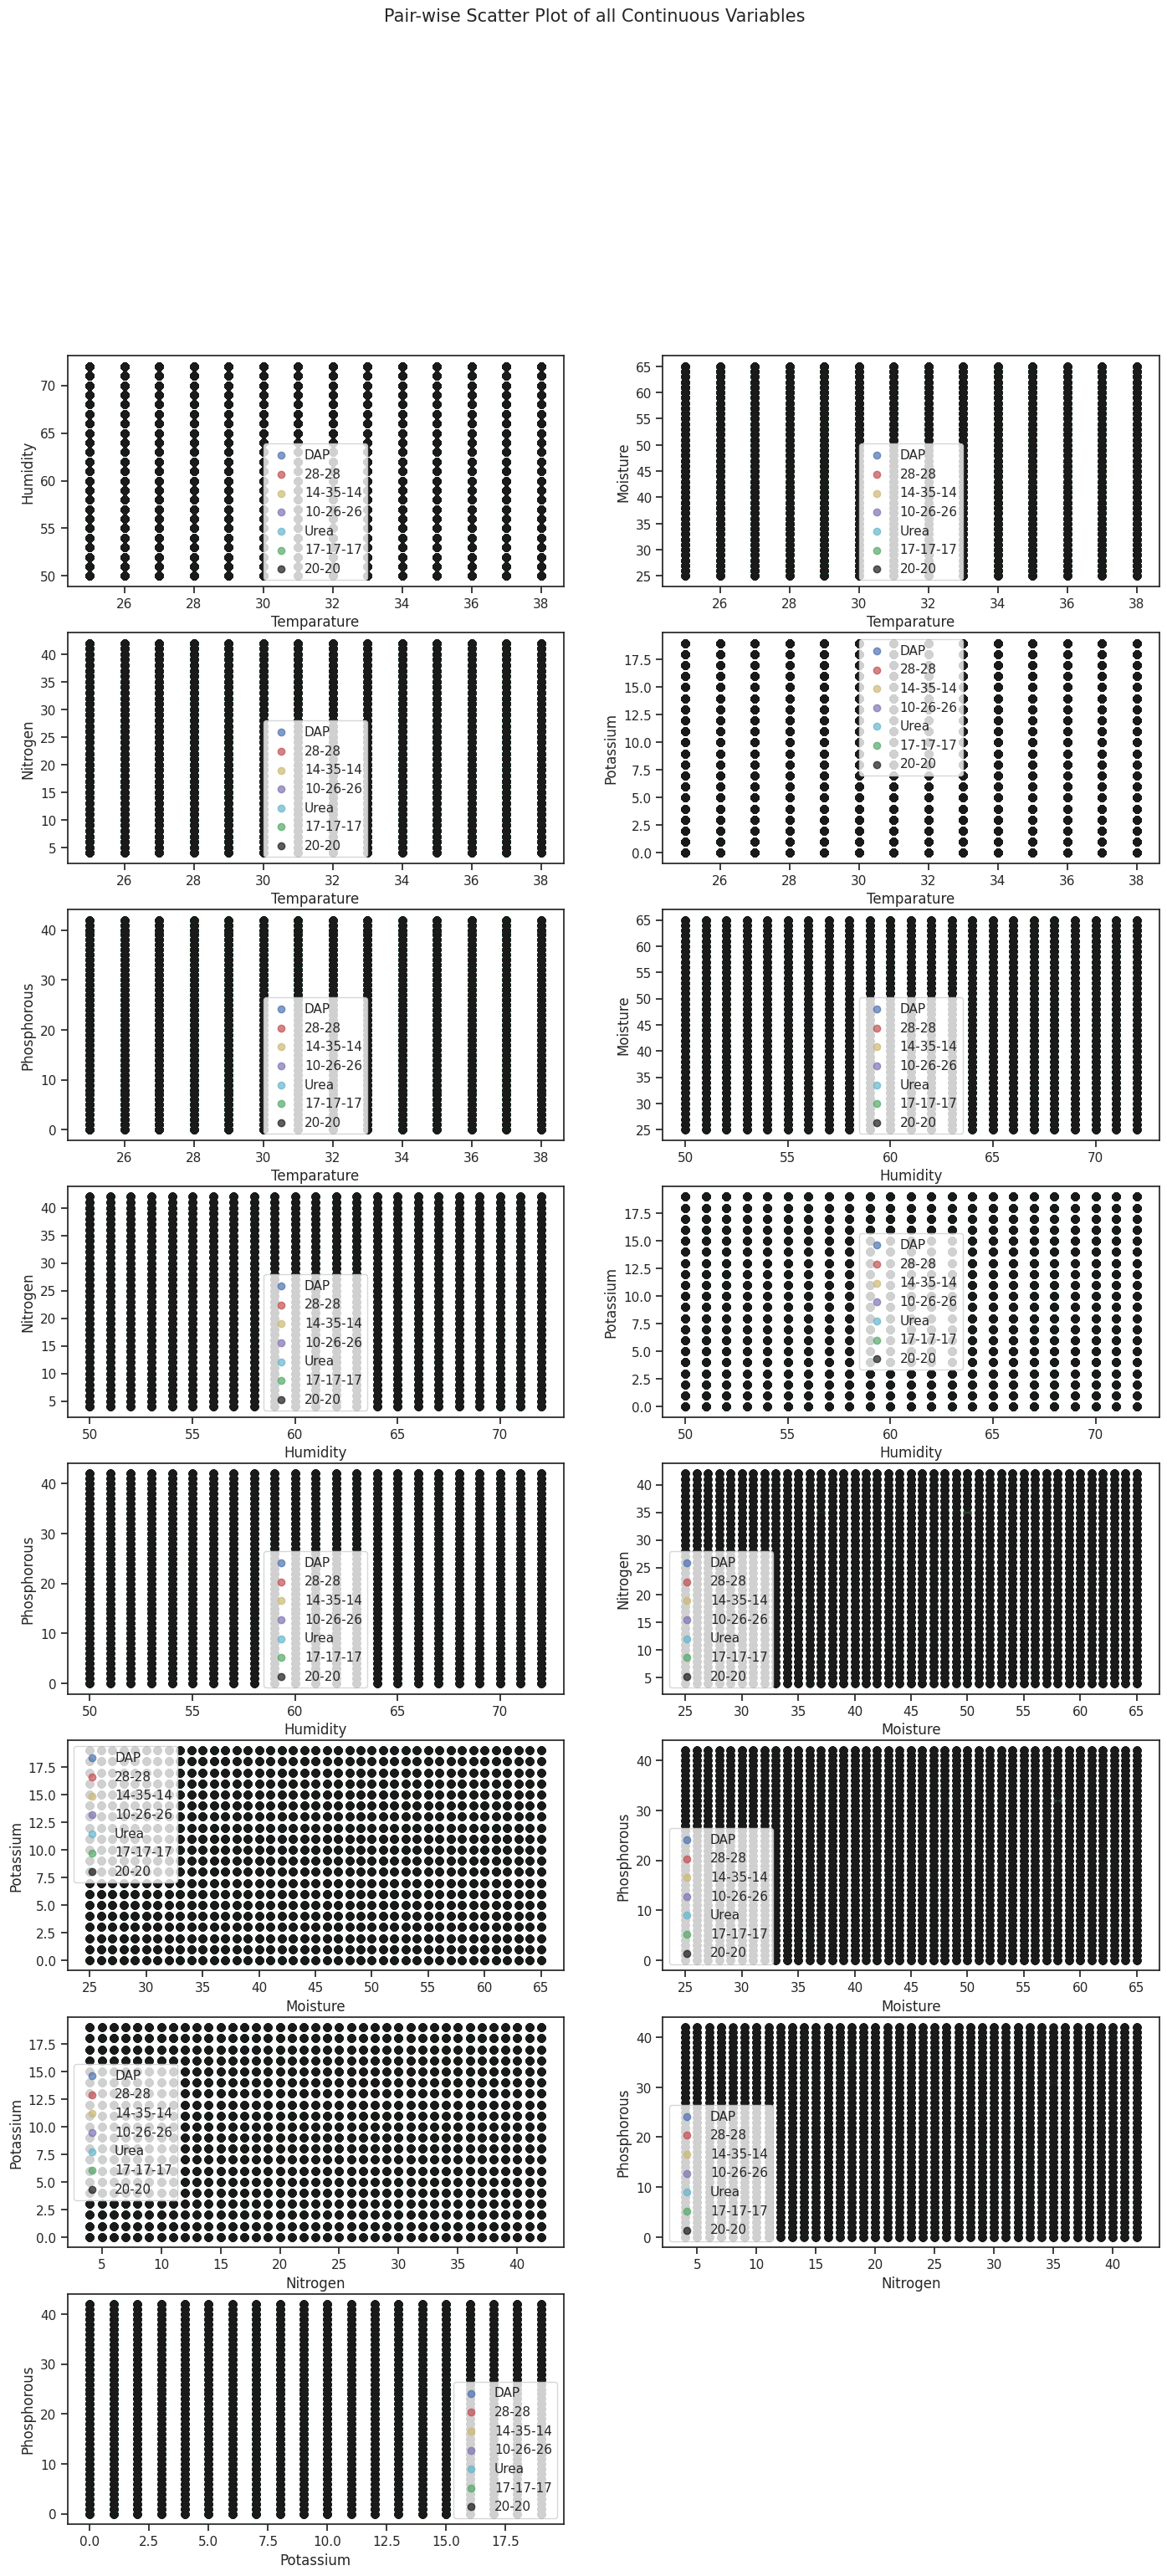

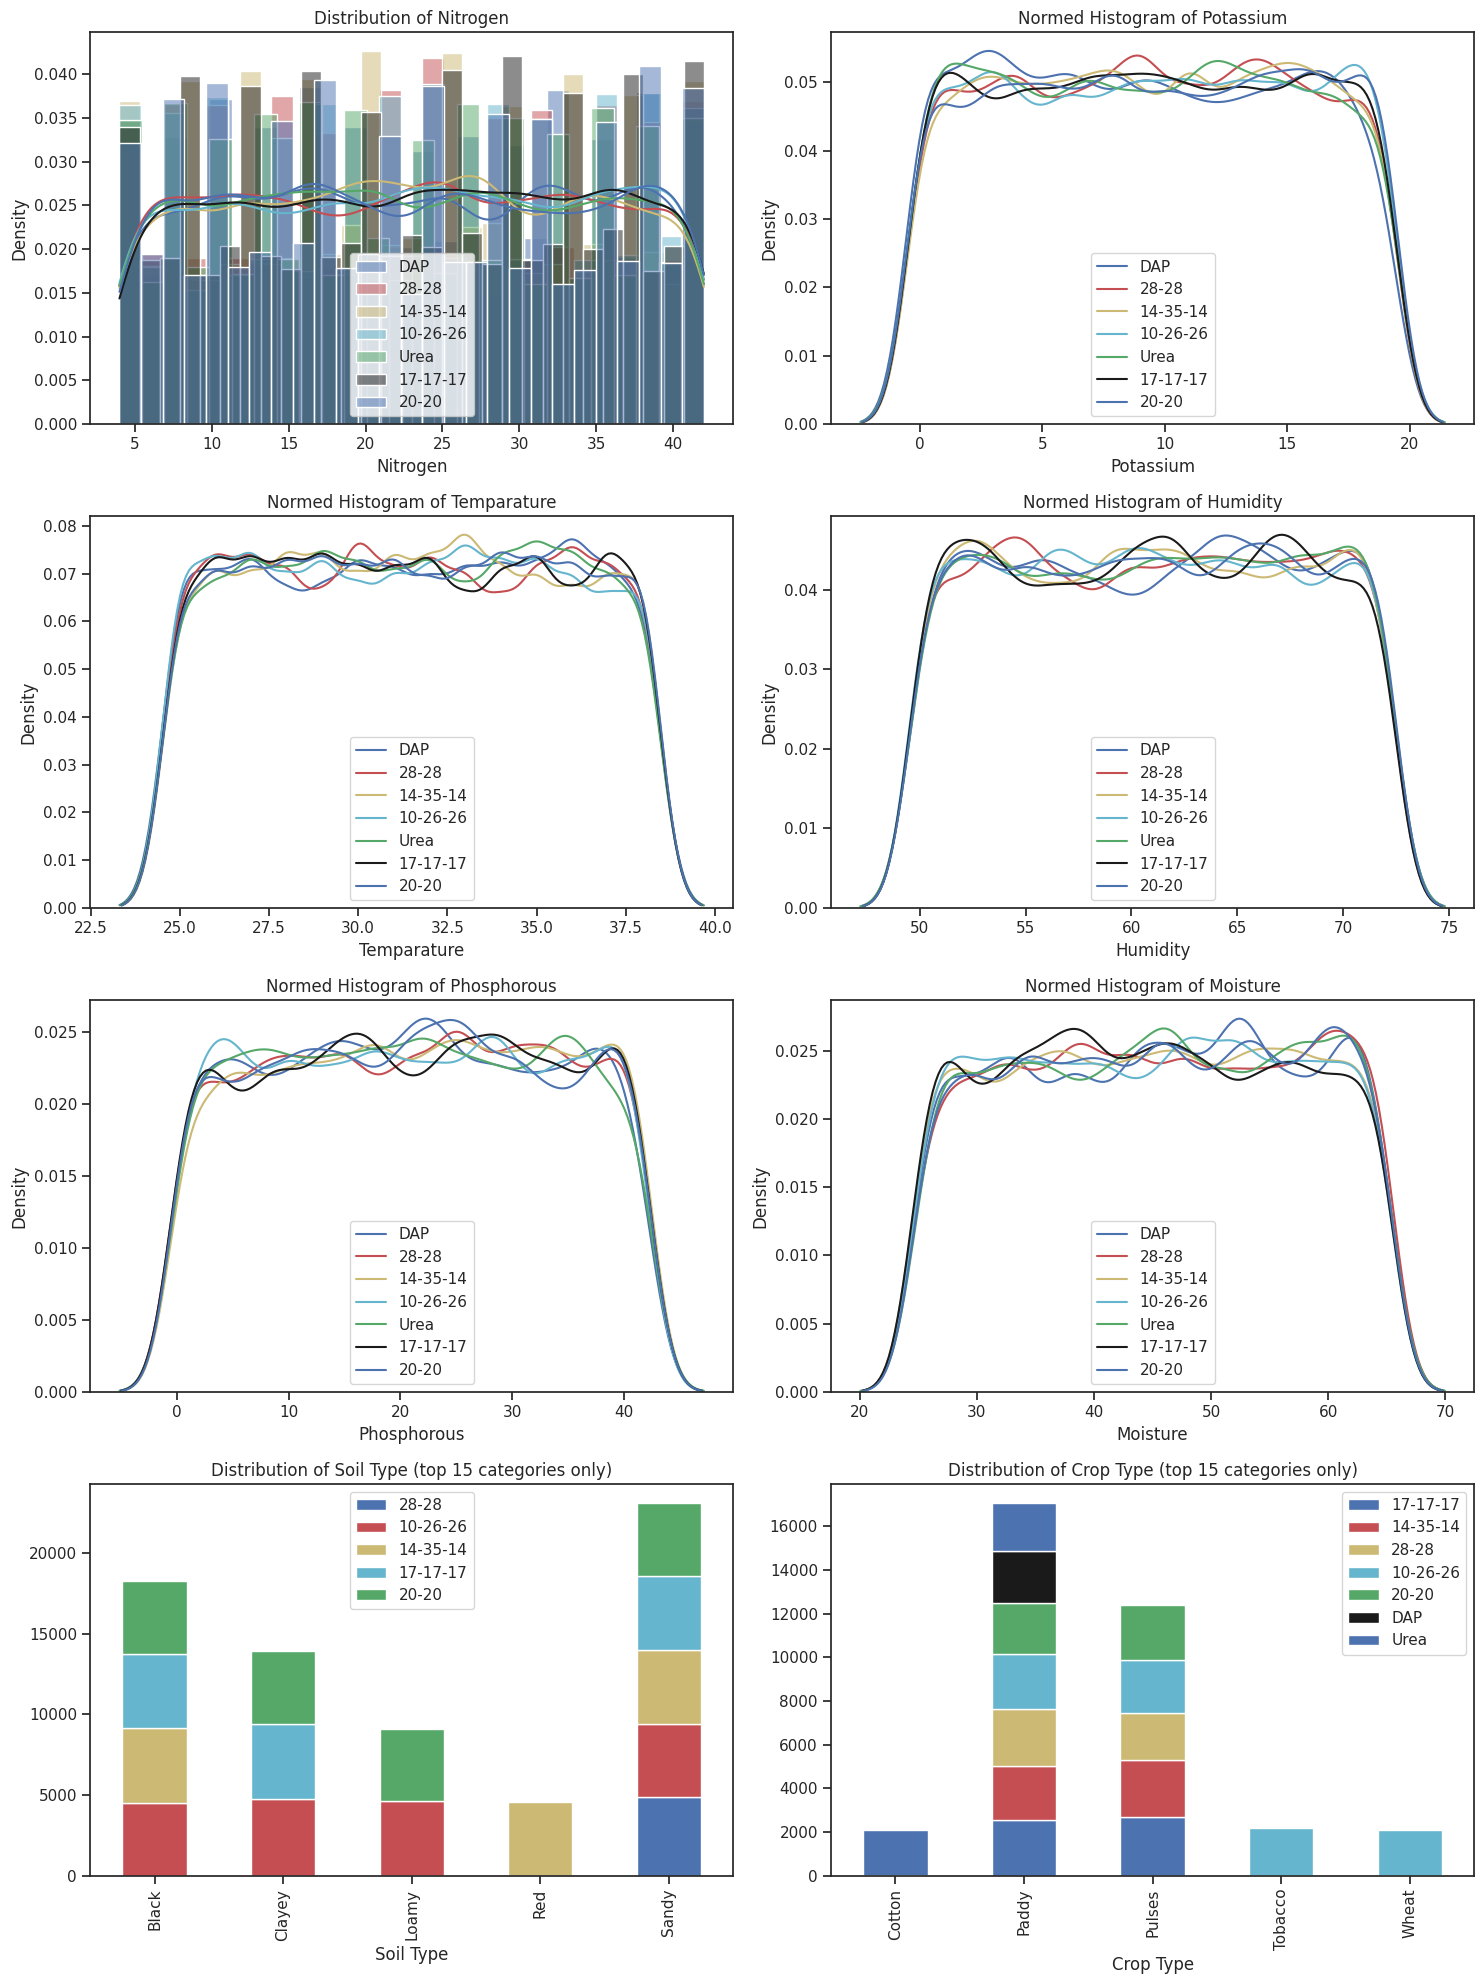

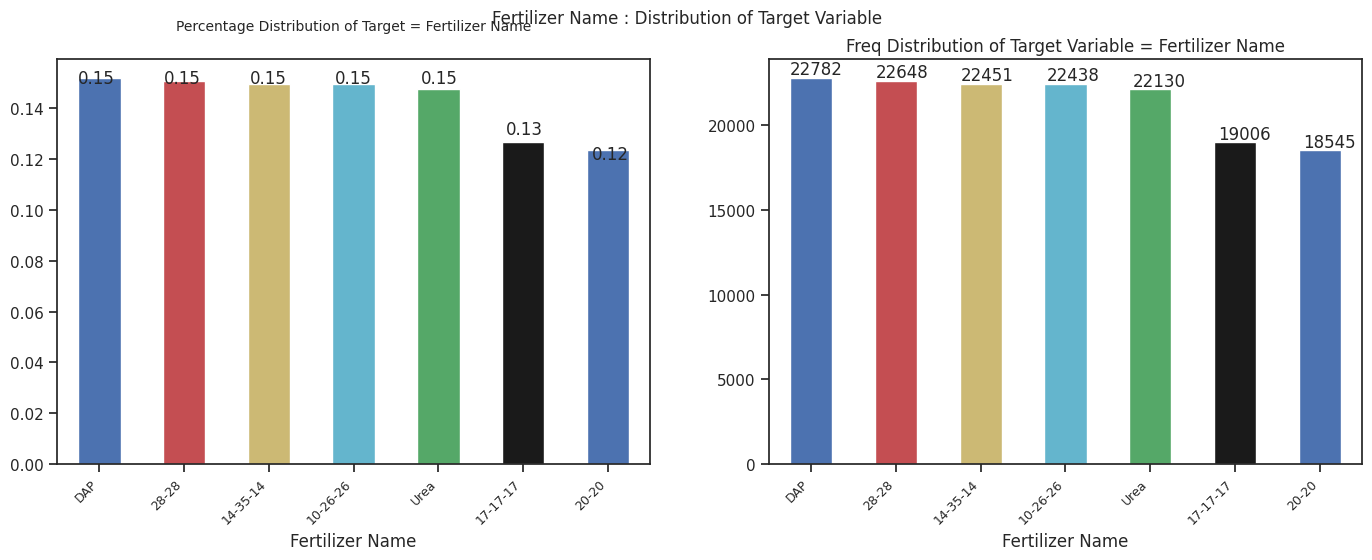

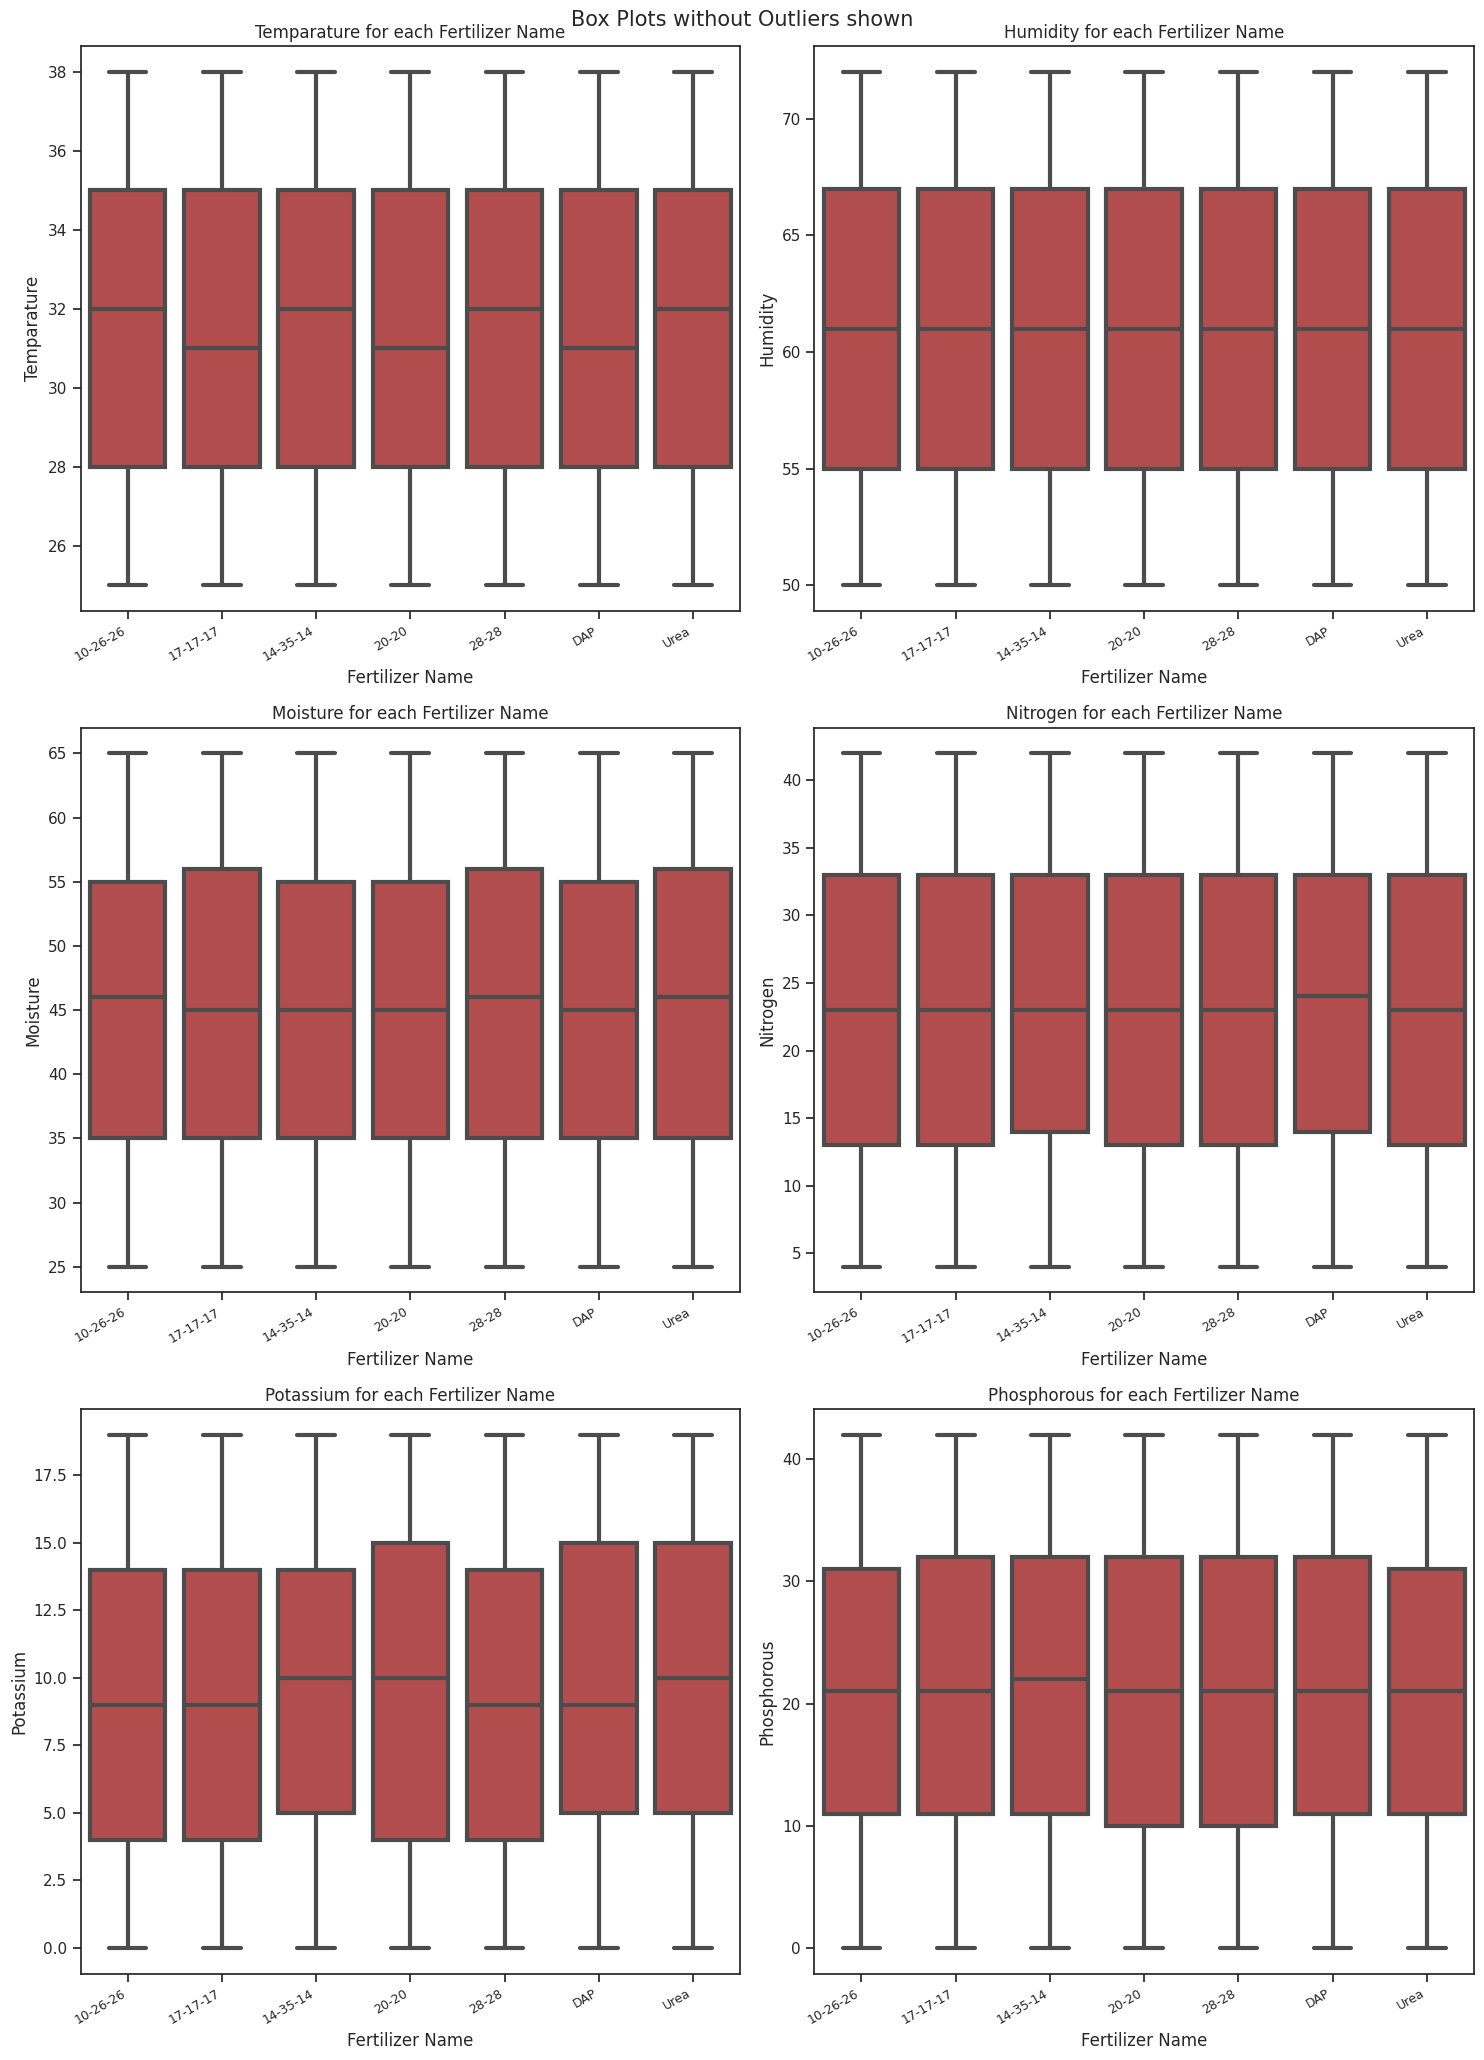

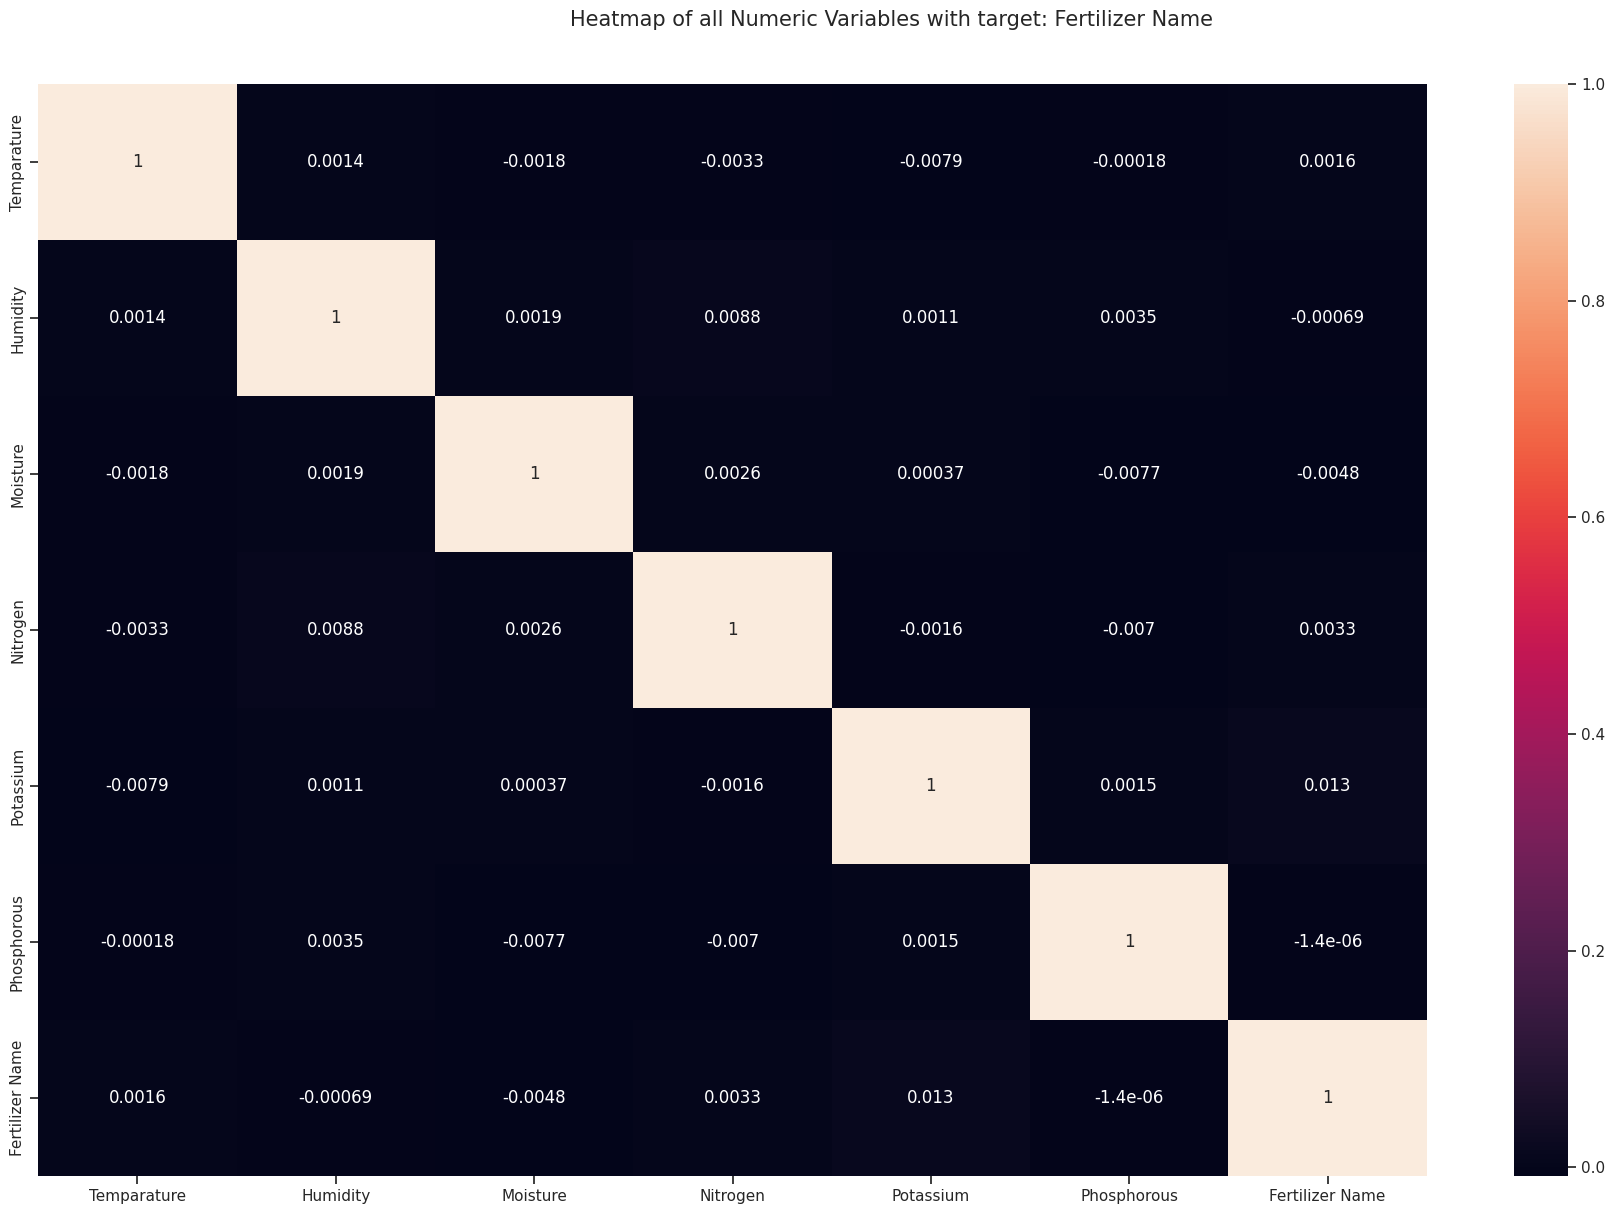

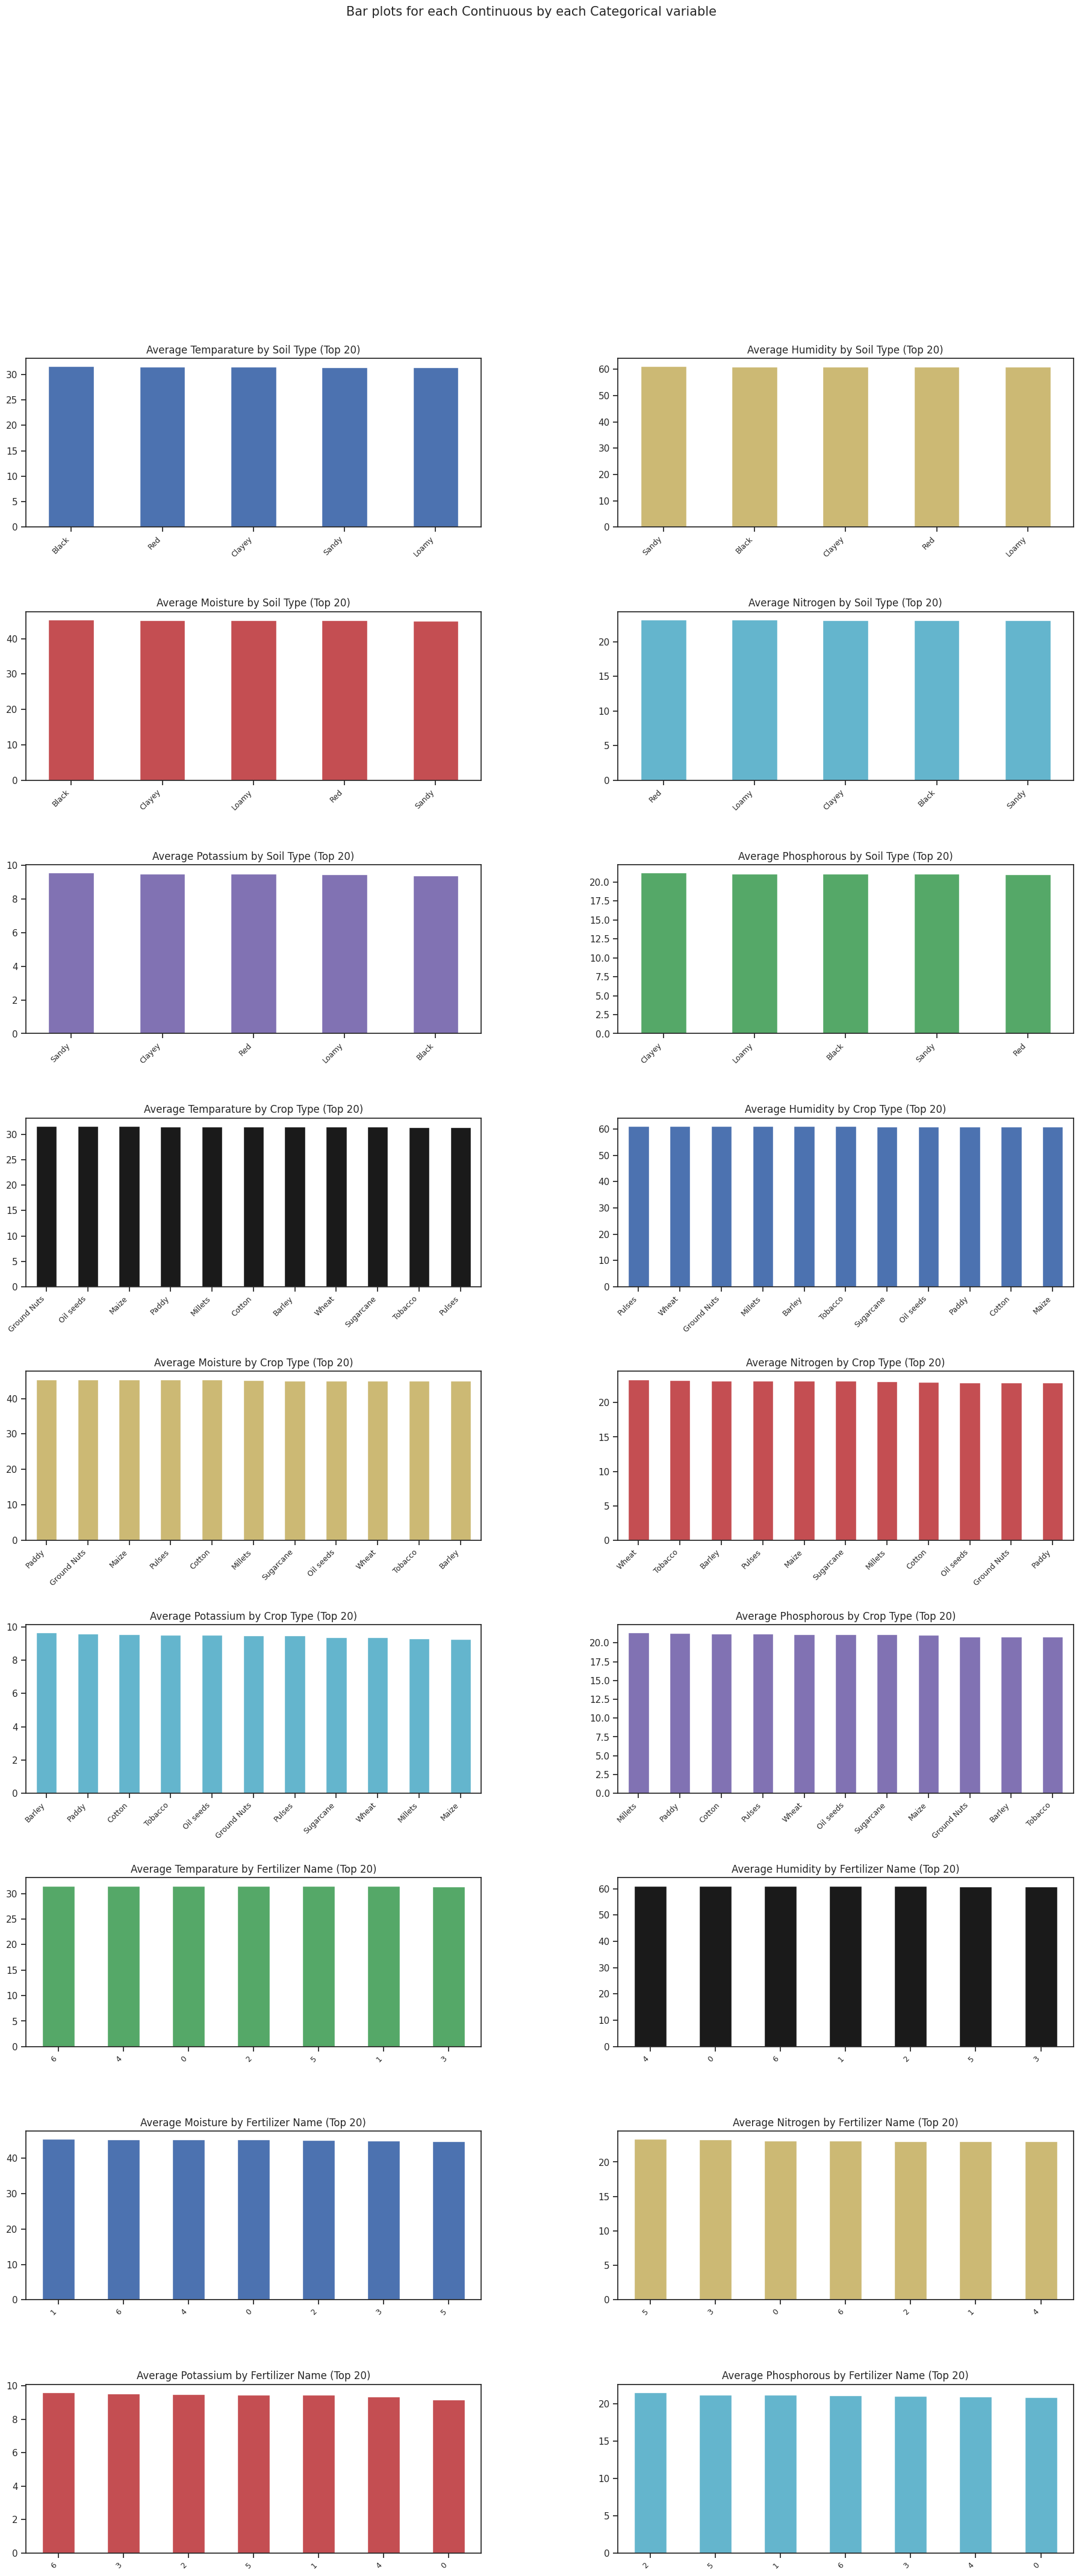

All Plots done
Time to run AutoViz = 120 seconds 

 ###################### AUTO VISUALIZATION Completed ########################


In [12]:
import pandas as pd
from autoviz.AutoViz_Class import AutoViz_Class

%matplotlib inline

AV = AutoViz_Class()

dfte = AV.AutoViz(
    filename="",              
    sep=",",                
    depVar="Fertilizer Name", 
    dfte=train,                 
    header=0,
    verbose=1,
    lowess=False,
    chart_format='svg',
    max_rows_analyzed=150000,
    max_cols_analyzed=30,
    save_plot_dir=None
)


<div style="border: 2px solid #1f77b4; border-radius: 10px; padding: 16px; background-color: #f0f8ff; box-shadow: 2px 2px 8px rgba(0,0,0,0.1); font-family: Arial, sans-serif;">

  <h2 style="color: #1f77b4; margin-top: 0;">🚀 Enjoyed the Notebook?</h2>

  <p style="font-size: 16px; color: #333;">
    If you found this helpful or insightful, please consider giving it an <strong style="color: #e63946;">⬆️ upvote</strong> to support the work!
  </p>

</div>
